In [ ]:
import marimo as mo

# Semi-Supervised Learning with GCNs

*August 4 2026*
*Training Workshop: Introduction to Deep Graph Learning*
*Ingo Scholtes, CAIDAS, Julius-Maximilians-Universität Würzburg (JMU), Germany*

We now consider semi-supervised node classification with GCNs, i.e. we apply GCNs to a data set that contains a large number of unlabeled nodes as well as a very small set of labeled nodes.

In [ ]:
import seaborn as sns
import torch
import torch_geometric
from matplotlib import pyplot as plt

import pathpyG as pp

plt.style.use('default')
sns.set_style("whitegrid")

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on', device)

Running on cpu


In [ ]:
class GraphConvolution(torch_geometric.nn.MessagePassing):
    """A graph convolution layer following (Kipf, Welling 2017)."""
    # Arguments passed to `propagate()`. pyG usually infers them from the source code of the class,
    # which is not possible for classes defined in marimo notebooks
    propagate_type = {'x': torch.Tensor, 'norm': torch.Tensor}

    def __init__(self, in_ch, out_ch):
        """Initialize the layer parameters."""
        super().__init__(aggr='add')

        # this linear function is used to transform node features 
        # into messages that are then "sent" to neighbors
        self.linear = torch.nn.Linear(in_ch, out_ch)
    
    def forward(self, x, edge_index):
        """Perform a graph convolution.

        This function uses the edges captured in edge_index, performs
        the graph convolution function according to (Kipf, Welling 2017)
        and propagates the transformed features along the edges of the graph.
        """
        # by adding self-loops, we ensure that aggregated messages from neighbors 
        # are combined with information from the node itself
        # this corresponds to matrix $\tilde{A}$ in (Kipf, Welling 2017)
        edge_index, _ = torch_geometric.utils.add_self_loops(edge_index, num_nodes=x.size(0))

        # we linearly transform the features of *all* nodes stored in x
        x = self.linear(x)

        # extract source and target nodes of all edges
        source, target = edge_index
    
        # compute the (in-)degrees $d_i$ of source nodes
        deg = torch_geometric.utils.degree(target, x.size(0), dtype=x.dtype)
        deg_inv_sqrt = deg.pow(-0.5)
        deg_inv_sqrt[deg_inv_sqrt == float('inf')] = 0

        # with this, the normalization to be applied in the propagation step can be expressed as
        # this corresponds to D^{-0.5} A * D^{-0.5} in (Kipf, Welling 2017)
        norm = deg_inv_sqrt[source] * deg_inv_sqrt[target]
    
        # the propagate function propagates messages along the edges of the graph
        # this function internally calls the functions: message(), aggregate() and update()
        # the normalization is applied in the message() function
        return self.propagate(edge_index, x=x, norm=norm)

    def message(self, x_j, norm):
        """Construct the message that is sent along each edge."""
        # x_j is a so-called **lifted** tensor which contains the source node features of each edge, 
        # i.e. it has a shape (m, out_ch) where m is the number of edges

        # a call to view(-1, 1) returns a reshaped tensor, where the second dimension 
        # is one and the first dimension is inferred automatically
        return norm.view(-1,1) * x_j

class GCN(torch.nn.Module):
    """A two-layer graph convolutional network."""

    def __init__(self, data: torch_geometric.data.Data, out_ch, hidden_dim_1=16):
        """Initialize the model parameters."""
        super().__init__()

        self.input_to_hidden1 = GraphConvolution(data.num_node_features, hidden_dim_1)

        self.hidden1_to_output =  GraphConvolution(hidden_dim_1, out_ch)
    
    def forward(self, x, edge_index):
        """Compute class probabilities for all nodes."""
        # first graph convolution -> map nodes to representations in hidden_dim dimensions
        x = self.input_to_hidden1(x, edge_index)

        # non-linear activation function
        x = torch.relu(x)

        # second graph convolution -> maps node representations to output classes
        x = self.hidden1_to_output(x, edge_index)

        # output class probabilities
        return torch.sigmoid(x)

In [ ]:
karate = pp.io.read_netzschleuder_graph(name='karate', network='78')
karate.data.node_groups = torch.tensor(karate.data.node_groups-1, dtype=torch.float)
karate.data.node_groups.unsqueeze_(-1)
karate.data.x = torch.eye(karate.n, dtype=torch.float32)
print(karate)
pp.plot(karate, edge_color='gray',  node_color=[karate["node_groups", v].item() for v in karate.nodes]);

/tmp/marimo_44015/__marimo__cell_lEQa_.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  karate.data.node_groups = torch.tensor(karate.data.node_groups-1, dtype=torch.float)


Undirected graph with 34 nodes and 78 edges
{   'Edge Attributes': {},
    'Graph Attributes': {   'analyses_average_degree': "<class 'float'>",
                            'analyses_degree_assortativity': "<class 'float'>",
                            'analyses_degree_std_dev': "<class 'float'>",
                            'analyses_diameter': "<class 'int'>",
                            'analyses_edge_properties': "<class 'list'>",
                            'analyses_edge_reciprocity': "<class 'float'>",
                            'analyses_global_clustering': "<class 'float'>",
                            'analyses_hashimoto_radius': "<class 'float'>",
                            'analyses_is_bipartite': "<class 'bool'>",
                            'analyses_is_directed': "<class 'bool'>",
                            'analyses_knn_proj_1': "<class 'float'>",
                            'analyses_knn_proj_2': "<class 'float'>",
                            'analyses_largest_compo

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "x4d8f9846c88e4ca9b2fe2e72e98c5f93"> </div>
<script charset="utf-8">
function render_plot_38428492167b4bb39895cb05983ae3a9() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "6"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "7"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "8"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "9"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#00224d", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#fde737", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}], "edges": [{"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-2", "source": "0", "target": "2"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-1", "source": "0", "target": "1"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-31", "source": "0", "target": "31"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-21", "source": "0", "target": "21"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-19", "source": "0", "target": "19"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-17", "source": "0", "target": "17"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-13", "source": "0", "target": "13"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-12", "source": "0", "target": "12"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-11", "source": "

tensor([0.2928], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.2684], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.2470], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.2281], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.2115], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1967], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1836], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1718], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1613], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1518], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1431], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1353], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1282], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1217], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1157], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1102], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1052], grad_fn=<SelectBackward0>) tensor([0.])
tensor([0.1005], grad_fn=<Selec

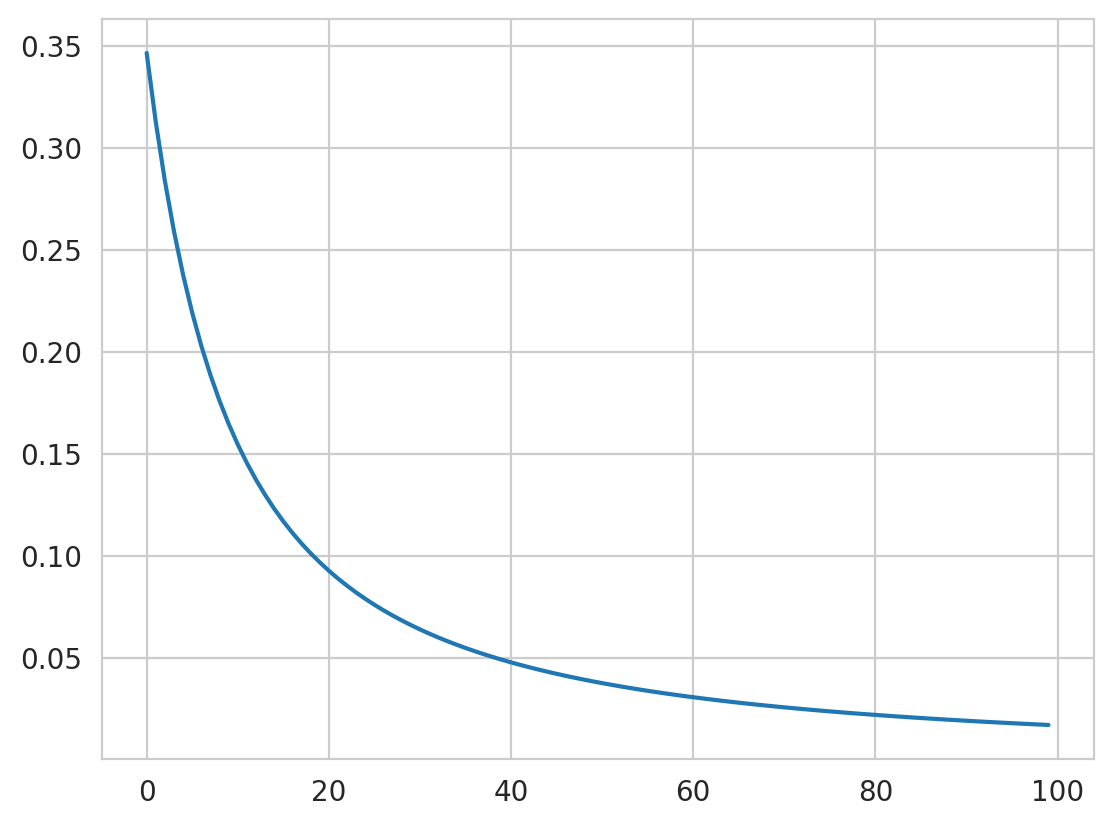

In [ ]:
labeled_nodes = [0]
model = GCN(karate.data, out_ch=1, hidden_dim_1=4)
_epochs = 100
_lrn_rate = 0.1
_optimizer = torch.optim.SGD(model.parameters(), lr=_lrn_rate)
_losses = []
model.train()
for _epoch in range(_epochs):
    _error = 0
    for _v in labeled_nodes:
        _i = karate.mapping.to_idx(_v)
        _optimizer.zero_grad()
        _output = model(karate.data.x, karate.data.edge_index)
        print(_output[_i], karate.data.node_groups[_i])
        _loss = torch.nn.functional.binary_cross_entropy(_output[_i], karate.data.node_groups[_i])
        _loss.backward()
        _optimizer.step()
        _error = _error + _loss.detach().numpy()
    _losses.append(_error)
plt.plot(range(_epochs), _losses)

In [ ]:
_output = model.forward(karate.data.x, karate.data.edge_index)
# we efficiently map probabilities to classes by rounding values to the 
# nearest integer, i.e. we obtain class 0 for probabilities smaller than 0.5
# and class 1 for probabilities larger than 0.5
_prediction = _output.round().long()
colors = {}
for _v in karate.nodes:
    _index = karate.mapping.to_idx(_v)
    if _v in labeled_nodes:
        colors[_v] = 'gray'
    elif _prediction[_index] == 0:
        colors[_v] = 'CornflowerBlue'  #print(output[index])
    else:  #print(decision(output[index]))
        colors[_v] = 'orange'
pp.plot(karate, edge_color='gray', node_color=[colors[v] for v in karate.nodes]);

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "x183b3621178c4736977bb0e7110fbbbe"> </div>
<script charset="utf-8">
function render_plot_2f83533584a94cf1b7eac575337e9d97() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "6"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "7"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "8"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "9"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}], "edges": [{"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-2", "source": "0", "target": "2"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-1", "source": "0", "target": "1"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-31", "source": "0", "target": "31"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-21", "source": "0", "target": "21"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-19", "source": "0", "target": "19"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-17", "source": "0", "target": "17"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-13", "source": "0", "target": "13"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-12", "source": "0", "target": "12"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-11", "source": "

In [ ]:
labeled_nodes_1 = [0, 33]
colors_1 = {}
for _v in karate.nodes:
    if _v == 0:
        colors_1[_v] = 'CornflowerBlue'
    elif _v == 33:
        colors_1[_v] = 'orange'
    else:
        colors_1[_v] = 'gray'
pp.plot(karate, edge_color='gray', node_color=[colors_1[v] for v in karate.nodes]);

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "xcfc1a2cba4514498ae1534ed974b72e2"> </div>
<script charset="utf-8">
function render_plot_0194471f41a5475189691e2906193e05() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "6"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "7"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "8"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "9"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}], "edges": [{"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-2", "source": "0", "target": "2"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-1", "source": "0", "target": "1"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-31", "source": "0", "target": "31"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-21", "source": "0", "target": "21"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-19", "source": "0", "target": "19"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-17", "source": "0", "target": "17"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-13", "source": "0", "target": "13"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-12", "source": "0", "target": "12"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-11", "source": "

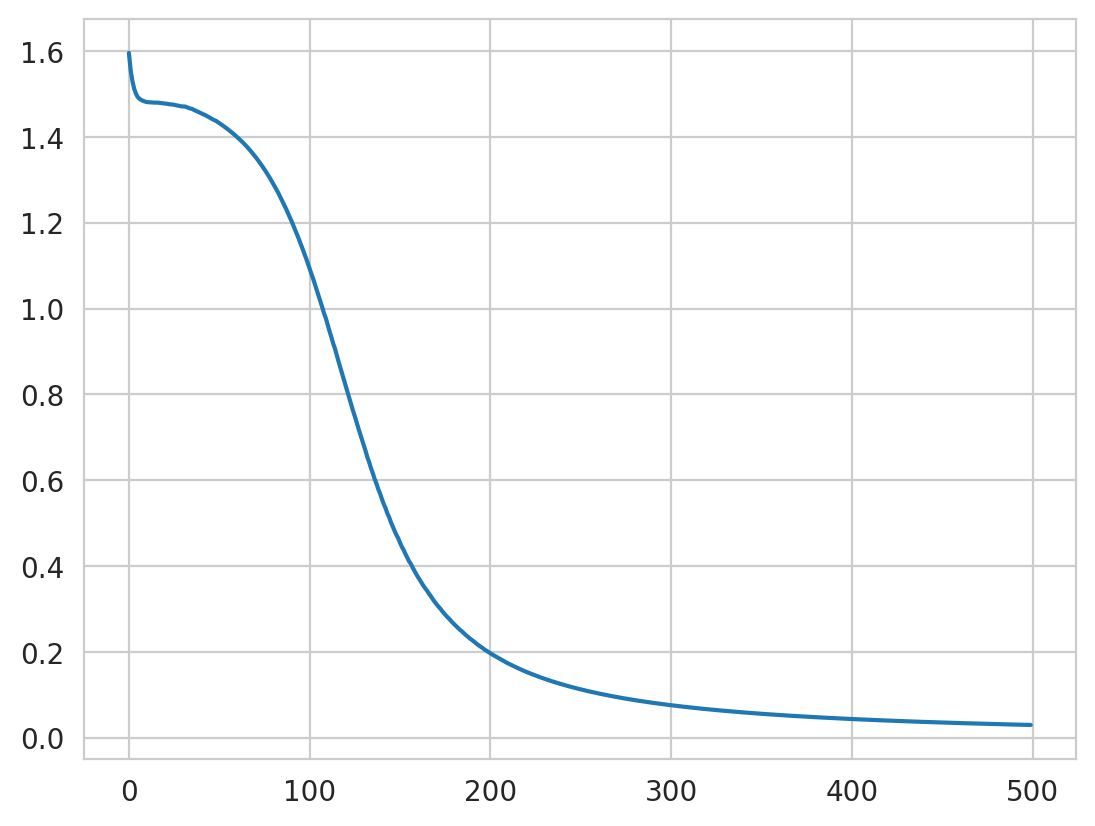

In [ ]:
model_1 = GCN(karate.data, out_ch=1, hidden_dim_1=4)
_epochs = 500
_lrn_rate = 0.1
_optimizer = torch.optim.SGD(model_1.parameters(), lr=_lrn_rate)
_losses = []
model_1.train()
for _epoch in range(_epochs):
    _error = 0
    for _v in labeled_nodes_1:
        _i = karate.mapping.to_idx(_v)
        _optimizer.zero_grad()
        _output = model_1(karate.data.x, karate.data.edge_index)
        _loss = torch.nn.functional.binary_cross_entropy(_output[_i], karate.data.node_groups[_i])
        _loss.backward()
        _optimizer.step()
        _error = _error + _loss.detach().numpy()
    _losses.append(_error)
plt.plot(range(_epochs), _losses)

In [ ]:
_output = model_1.forward(karate.data.x, karate.data.edge_index)
_prediction = _output.round().long()
for _v in karate.nodes:
    _index = karate.mapping.to_idx(_v)
    if _v in labeled_nodes_1:
        colors_1[_v] = 'gray'
    elif _prediction[_index] == 0:
        colors_1[_v] = 'CornflowerBlue'
    else:
        colors_1[_v] = 'orange'
pp.plot(karate, edge_color='gray', node_color=[colors_1[v] for v in karate.nodes]);

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "x81cab7a72d8d49998cbb7e2065bbe283"> </div>
<script charset="utf-8">
function render_plot_b345a64dd3604a89b8c2a2e3675789ee() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "6"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "7"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "8"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "9"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}], "edges": [{"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-2", "source": "0", "target": "2"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-1", "source": "0", "target": "1"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-31", "source": "0", "target": "31"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-21", "source": "0", "target": "21"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-19", "source": "0", "target": "19"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-17", "source": "0", "target": "17"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-13", "source": "0", "target": "13"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-12", "source": "0", "target": "12"}, {"color": "#808080", "size": 2, "opacity": 0.5, "image": null, "uid": "0-11", "source": "